In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
# 1. Numerical computing
import numpy as np

# 2. Data manipulation
import pandas as pd

# 3. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. Statistical analysis
from scipy import stats

# 5. Data preprocessing
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder,
    OrdinalEncoder,
    FunctionTransformer,
    Binarizer,
    KBinsDiscretizer
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 6. Linear Regression
from sklearn.linear_model import LinearRegression

# 7. Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 8. Saving the model
import joblib
# 9. For cross vlave model
from sklearn.model_selection import (
    cross_val_score,
    cross_validate,
    KFold,
    cross_val_predict
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV
)


In [4]:
df=pd.read_csv("student-por.csv")

In [5]:
df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.shape


(649, 33)

In [8]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [10]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


In [11]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [12]:
df=df[['sex',
    'age',
    'studytime',
    'failures',
    'schoolsup',
    'internet',
    'absences',
    'G1',
    'G2',
    'G3']]

In [13]:
df.shape


(649, 10)

In [14]:
df.columns

Index(['sex', 'age', 'studytime', 'failures', 'schoolsup', 'internet',
       'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sex        649 non-null    object
 1   age        649 non-null    int64 
 2   studytime  649 non-null    int64 
 3   failures   649 non-null    int64 
 4   schoolsup  649 non-null    object
 5   internet   649 non-null    object
 6   absences   649 non-null    int64 
 7   G1         649 non-null    int64 
 8   G2         649 non-null    int64 
 9   G3         649 non-null    int64 
dtypes: int64(7), object(3)
memory usage: 50.8+ KB


In [16]:
df.describe

<bound method NDFrame.describe of     sex  age  studytime  failures schoolsup internet  absences  G1  G2  G3
0     F   18          2         0       yes       no         4   0  11  11
1     F   17          2         0        no      yes         2   9  11  11
2     F   15          2         0       yes      yes         6  12  13  12
3     F   15          3         0        no      yes         0  14  14  14
4     F   16          2         0        no       no         0  11  13  13
..   ..  ...        ...       ...       ...      ...       ...  ..  ..  ..
644   F   19          3         1        no      yes         4  10  11  10
645   F   18          2         0        no      yes         4  15  15  16
646   F   18          2         0        no       no         6  11  12   9
647   M   17          1         0        no      yes         6  10  10  10
648   M   18          1         0        no      yes         4  10  11  11

[649 rows x 10 columns]>

In [17]:

df.sample()

,sex,age,studytime,failures,schoolsup,internet,absences,G1,G2,G3
196,F,17,2,0,no,no,0,17,18,17


In [18]:
df.nunique()

sex           2
age           8
studytime     4
failures      4
schoolsup     2
internet      2
absences     24
G1           17
G2           16
G3           17
dtype: int64

In [19]:
categorical=['sex','schoolsup','sex']

In [20]:
numerical=['age','studytime','failures','absences','G1','G2','G3']

In [21]:
df[numerical].describe()

,age,studytime,failures,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,1.930663,0.221880,3.659476,11.399076,11.570108,11.906009
std,1.218138,0.829510,0.593235,4.640759,2.745265,2.913639,3.230656
min,15.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,1.000000,0.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,0.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,2.000000,0.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,3.000000,32.000000,19.000000,19.000000,19.000000


In [22]:
%pip install ydata-profiling

Note: you may need to restart the kernel to use updated packages.


In [23]:
from ydata_profiling import ProfileReport
prof=ProfileReport(df)
prof.to_file(output_file='output.html')

C:\Users\asus\anaconda3\envs\StudentPerformance_py312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\asus\AppData\Local\Temp\ipykernel_23148\3209420491.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport
Export report to file: 100%|██████████| 1/1 [00:00<00:00, 26.08it/s]


In [24]:
from IPython.display import IFrame, display

display(IFrame("output.html", width="100%", height=600))


In [25]:
zero_students = df[df['G3'] == 0]

zero_students

,sex,age,studytime,failures,schoolsup,internet,absences,G1,G2,G3
163,M,18,1,2,no,yes,0,11,9,0
440,M,16,2,0,no,no,0,7,0,0
519,M,16,2,0,no,yes,0,8,7,0
563,M,17,1,1,no,no,0,7,0,0
567,M,18,1,1,no,yes,0,4,0,0
583,F,18,1,1,no,yes,0,8,6,0
586,F,17,2,0,yes,yes,0,8,8,0
597,F,18,2,1,no,no,0,9,0,0
603,F,18,2,0,no,yes,0,5,0,0
605,F,19,1,1,no,no,0,5,0,0


In [26]:
zero_students[['G1', 'G2', 'G3']]


,G1,G2,G3
163,11,9,0
440,7,0,0
519,8,7,0
563,7,0,0
567,4,0,0
583,8,6,0
586,8,8,0
597,9,0,0
603,5,0,0
605,5,0,0


In [27]:
df['total_score'] = df['G1'] + df['G2'] + df['G3']

df['percentage'] = (df['total_score'] / 60) * 100

df['percentage'] = df['percentage'].round(2)

In [28]:
df.drop(columns=['G1','G2','G3'])

,sex,age,studytime,failures,schoolsup,internet,absences,total_score,percentage
0,F,18,2,0,yes,no,4,22,36.67
1,F,17,2,0,no,yes,2,31,51.67
2,F,15,2,0,yes,yes,6,37,61.67
3,F,15,3,0,no,yes,0,42,70.00
4,F,16,2,0,no,no,0,37,61.67
...,...,...,...,...,...,...,...,...,...
644,F,19,3,1,no,yes,4,31,51.67
645,F,18,2,0,no,yes,4,46,76.67
646,F,18,2,0,no,no,6,32,53.33
647,M,17,1,0,no,yes,6,30,50.00


In [29]:
df.columns

Index(['sex', 'age', 'studytime', 'failures', 'schoolsup', 'internet',
       'absences', 'G1', 'G2', 'G3', 'total_score', 'percentage'],
      dtype='object')

In [30]:
df.duplicated().sum()

np.int64(16)

In [31]:
df.sample()

,sex,age,studytime,failures,schoolsup,internet,absences,G1,G2,G3,total_score,percentage
151,M,16,3,0,no,yes,0,15,13,13,41,68.33


In [32]:
duplicates = df[df.duplicated(keep=False)]

duplicates.sort_values(by=list(df.columns))

,sex,age,studytime,failures,schoolsup,internet,absences,G1,G2,G3,total_score,percentage
153,F,15,3,0,no,yes,2,13,13,13,39,65.00
165,F,15,3,0,no,yes,2,13,13,13,39,65.00
50,F,16,2,0,no,yes,0,14,13,13,40,66.67
187,F,16,2,0,no,yes,0,14,13,13,40,66.67
252,F,16,2,0,no,yes,0,14,13,13,40,66.67
59,F,16,2,0,no,yes,2,16,15,16,47,78.33
65,F,16,2,0,no,yes,2,16,15,16,47,78.33
234,F,17,2,0,no,yes,0,11,10,11,32,53.33
485,F,17,2,0,no,yes,0,11,10,11,32,53.33
355,F,17,2,0,no,yes,2,11,12,14,37,61.67


In [33]:

X = df[
    ['sex', 'age', 'studytime', 'failures',
     'schoolsup', 'internet', 'absences',]
]


y = df['percentage']

In [34]:
X.describe()

,age,studytime,failures,absences
count,649.000000,649.000000,649.000000,649.000000
mean,16.744222,1.930663,0.221880,3.659476
std,1.218138,0.829510,0.593235,4.640759
min,15.000000,1.000000,0.000000,0.000000
25%,16.000000,1.000000,0.000000,0.000000
50%,17.000000,2.000000,0.000000,2.000000
75%,18.000000,2.000000,0.000000,6.000000
max,22.000000,4.000000,3.000000,32.000000


In [35]:
X.describe(include='object')

,sex,schoolsup,internet
count,649,649,649
unique,2,2,2
top,F,no,yes
freq,383,581,498


In [36]:
X.skew(numeric_only=True)

age          0.416795
studytime    0.699619
failures     3.092699
absences     2.020694
dtype: float64

In [37]:
X.kurt(numeric_only=True)

age          0.071509
studytime    0.037846
failures     9.824409
absences     5.781078
dtype: float64

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [39]:
for col in ['age', 'absences']:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[col] < lower) |
        (X_train[col] > upper)
    ]

    print(f"\nColumn: {col}")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Potential outliers:", len(outliers))


Column: age
Lower limit: 13.0
Upper limit: 21.0
Potential outliers: 1

Column: absences
Lower limit: -9.0
Upper limit: 15.0
Potential outliers: 18


In [40]:
age_outliers = X_train[
    (X_train['age'] < 13) |
    (X_train['age'] > 21)
]

absence_outliers = X_train[
    (X_train['absences'] < -9) |
    (X_train['absences'] > 15)
]

print("Age outliers:")
display(age_outliers)

print("Absence outliers:")
display(absence_outliers)

Age outliers:


,sex,age,studytime,failures,schoolsup,internet,absences
279,M,22,1,3,no,yes,12


Absence outliers:


,sex,age,studytime,failures,schoolsup,internet,absences
155,M,17,1,0,no,yes,22
256,M,18,1,1,no,yes,26
211,M,16,1,0,no,yes,16
326,M,17,1,0,no,yes,18
263,M,18,2,0,no,yes,16
103,F,15,2,0,yes,yes,16
253,F,18,2,1,no,yes,18
150,F,15,2,0,no,no,24
325,M,17,1,0,no,yes,22
254,F,18,2,1,no,yes,16


In [44]:
%matplotlib inline

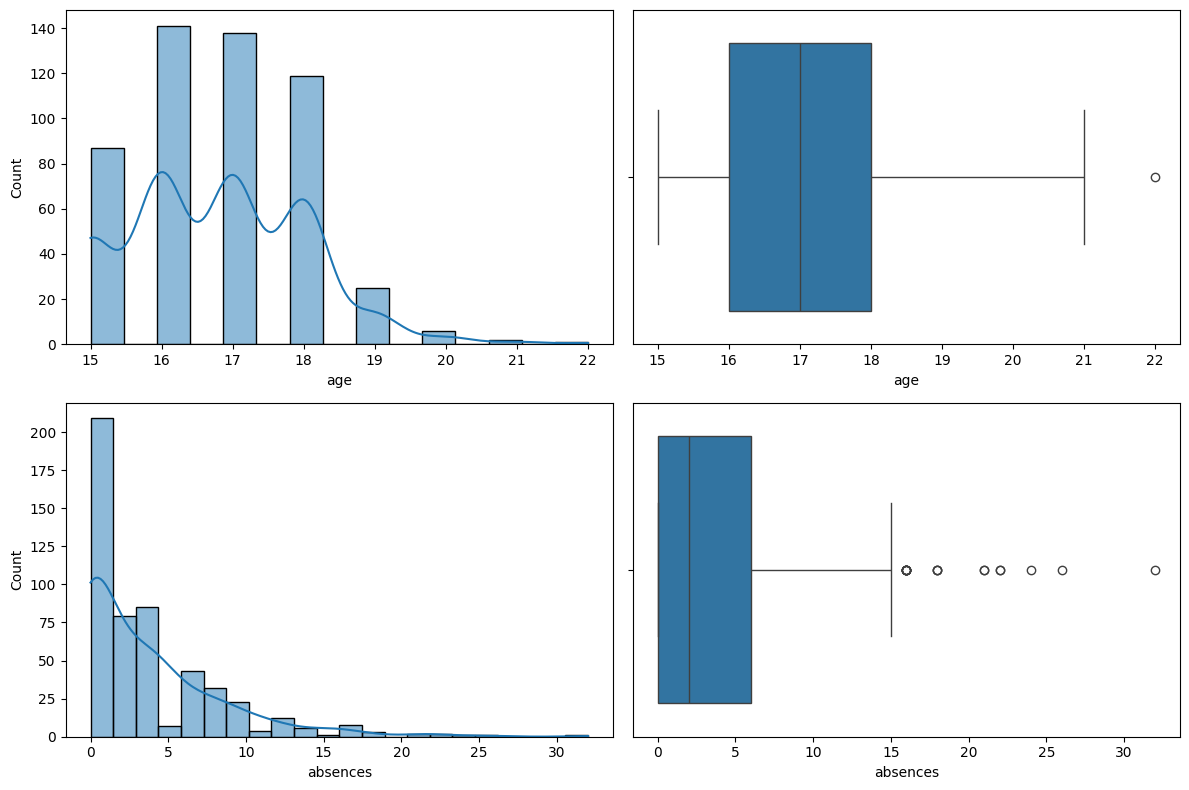

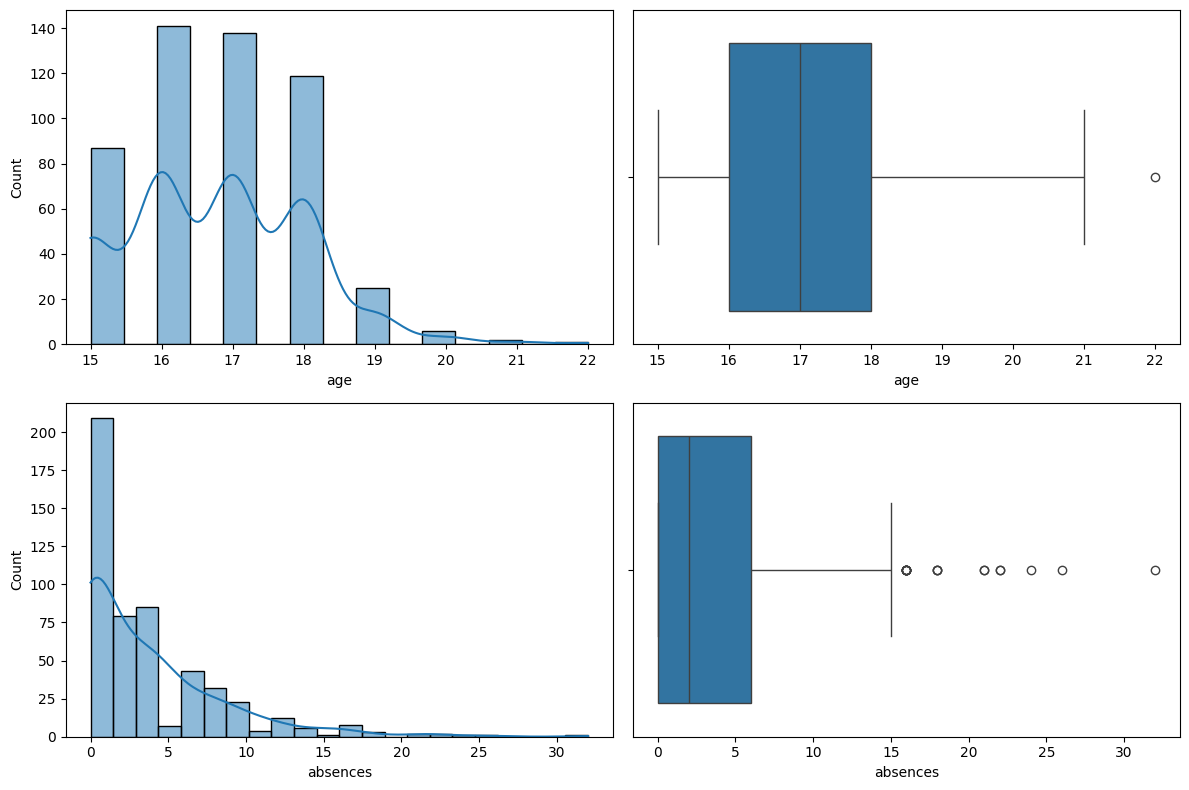

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(X_train['age'], kde=True, ax=axes[0, 0])
sns.boxplot(x=X_train['age'], ax=axes[0, 1])

sns.histplot(X_train['absences'], kde=True, ax=axes[1, 0])
sns.boxplot(x=X_train['absences'], ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [46]:
X_train_cap = X_train.copy()

for col in ['age', 'absences']:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_train_cap[col] = X_train[col].clip(
        lower=lower,
        upper=upper
    )

In [47]:
comparison = pd.DataFrame({
    'Original': X_train[['age', 'absences']].max(),
    'Capped': X_train_cap[['age', 'absences']].max()
})

print(comparison)
print("Original shape:", X_train.shape)
print("Capped shape:", X_train_cap.shape)

          Original  Capped
age             22      21
absences        32      15
Original shape: (519, 7)
Capped shape: (519, 7)


In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_std = scaler.fit_transform(
    X_train[['age', 'absences']]
)

X_test_std = scaler.transform(
    X_test[['age', 'absences']]
)

X_train_std = pd.DataFrame(
    X_train_std,
    columns=['age', 'absences'],
    index=X_train.index
)

X_train_std.describe()

,age,absences
count,5.190000e+02,5.190000e+02
mean,-7.102005e-16,2.224724e-17
std,1.000965e+00,1.000965e+00
min,-1.438267e+00,-7.896158e-01
25%,-6.295340e-01,-7.896158e-01
50%,1.791990e-01,-3.618385e-01
75%,9.879321e-01,4.937159e-01
max,4.222864e+00,6.054820e+00


In [49]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()

X_train_norm = minmax.fit_transform(
    X_train[['age', 'absences']]
)

X_test_norm = minmax.transform(
    X_test[['age', 'absences']]
)

X_train_norm = pd.DataFrame(
    X_train_norm,
    columns=['age', 'absences'],
    index=X_train.index
)

X_train_norm.describe()

,age,absences
count,519.000000,519.000000
mean,0.254060,0.115366
std,0.176814,0.146245
min,0.000000,0.000000
25%,0.142857,0.000000
50%,0.285714,0.062500
75%,0.428571,0.187500
max,1.000000,1.000000


In [50]:
from sklearn.preprocessing import Normalizer

normalizer = Normalizer()

X_train_row_norm = normalizer.fit_transform(
    X_train[['age', 'absences']]
)

X_train_row_norm[:5]

array([[1.        , 0.        ],
       [0.9701425 , 0.24253563],
       [0.99388373, 0.11043153],
       [1.        , 0.        ],
       [0.98478356, 0.17378533]])

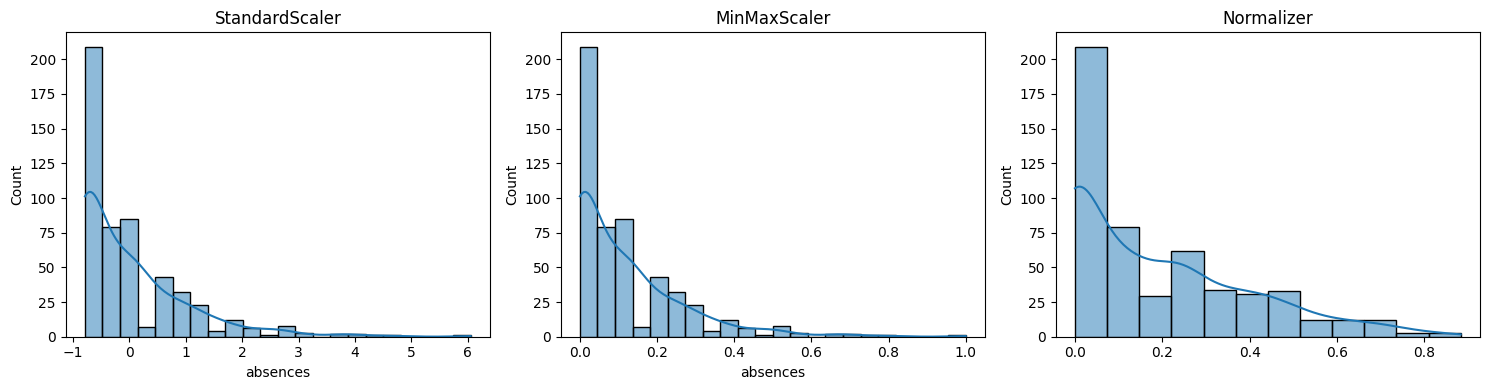

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(X_train_std['absences'], kde=True, ax=axes[0])
axes[0].set_title('StandardScaler')

sns.histplot(X_train_norm['absences'], kde=True, ax=axes[1])
axes[1].set_title('MinMaxScaler')

sns.histplot(X_train_row_norm[:, 1], kde=True, ax=axes[2])
axes[2].set_title('Normalizer')

plt.tight_layout()
plt.show()

In [52]:
X_train_log = X_train.copy()

X_train_log['absences'] = np.log1p(
    X_train['absences']
)

print("Original skewness:",
      X_train['absences'].skew())

print("Log skewness:",
      X_train_log['absences'].skew())

Original skewness: 1.9473216734660854
Log skewness: 0.18474225437378758


In [53]:
X_train_sqrt = X_train.copy()

X_train_sqrt['absences'] = np.sqrt(
    X_train['absences']
)

print("Original skewness:",
      X_train['absences'].skew())

print("Square root skewness:",
      X_train_sqrt['absences'].skew())

Original skewness: 1.9473216734660854
Square root skewness: 0.38962683896526473


In [54]:
X_train_reciprocal = X_train.copy()

X_train_reciprocal['absences'] = (
    1 / (X_train['absences'] + 1)
)

print("Original skewness:",
      X_train['absences'].skew())

print("Reciprocal skewness:",
      X_train_reciprocal['absences'].skew())

Original skewness: 1.9473216734660854
Reciprocal skewness: 0.3560648000633855


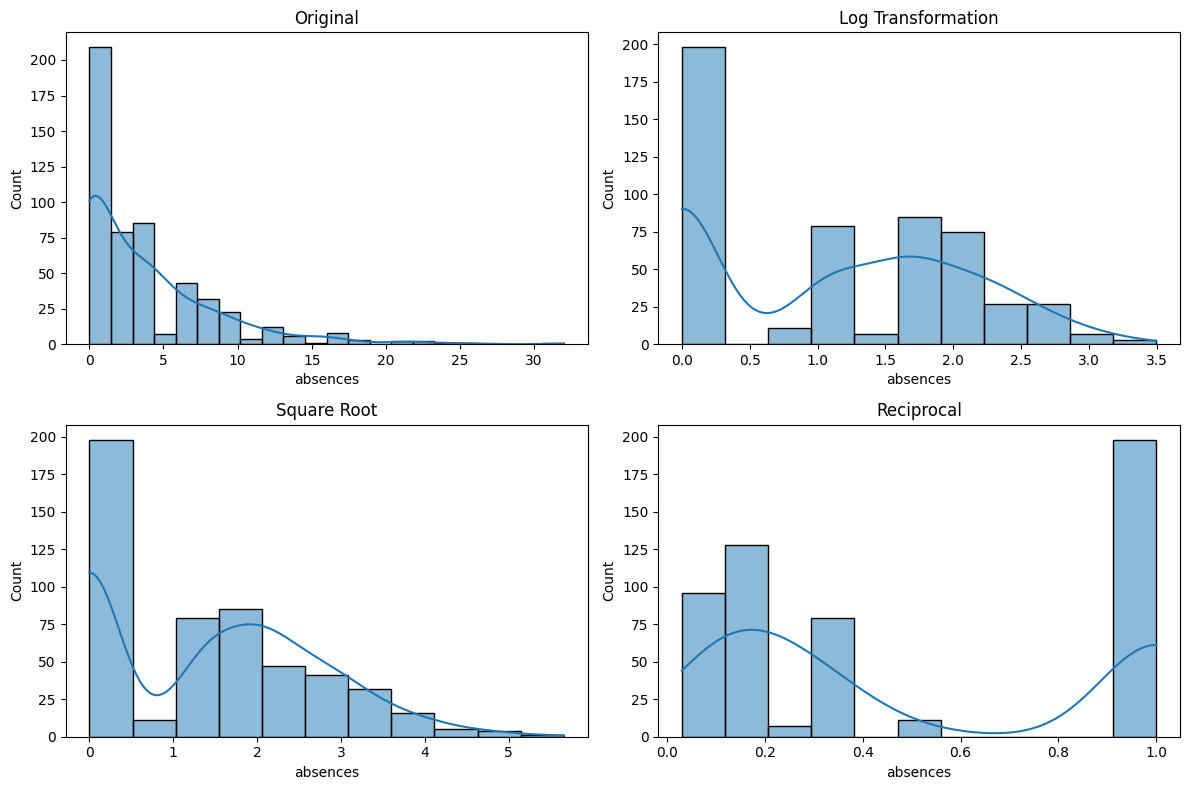

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(X_train['absences'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Original')

sns.histplot(X_train_log['absences'], kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Log Transformation')

sns.histplot(X_train_sqrt['absences'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Square Root')

sns.histplot(X_train_reciprocal['absences'], kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Reciprocal')

plt.tight_layout()
plt.show()

In [56]:
from sklearn.preprocessing import PowerTransformer

pt_yeo = PowerTransformer(
    method='yeo-johnson',
    standardize=False
)

yeo = pt_yeo.fit_transform(
    X_train[['absences']]
)

print("Yeo-Johnson skewness:",
      pd.Series(yeo.ravel()).skew())

Yeo-Johnson skewness: 0.061048011363229696


In [57]:
pt_box = PowerTransformer(
    method='box-cox',
    standardize=False
)

box = pt_box.fit_transform(
    X_train[['absences']] + 1
)

print("Box-Cox skewness:",
      pd.Series(box.ravel()).skew())

Box-Cox skewness: 0.06104802348907317


In [65]:
from sklearn.preprocessing import FunctionTransformer

ft = FunctionTransformer(
    np.log1p,
    inverse_func=np.expm1
)

log_values = ft.fit_transform(
    X_train[['absences']]
)

log_values = np.asarray(log_values).ravel()

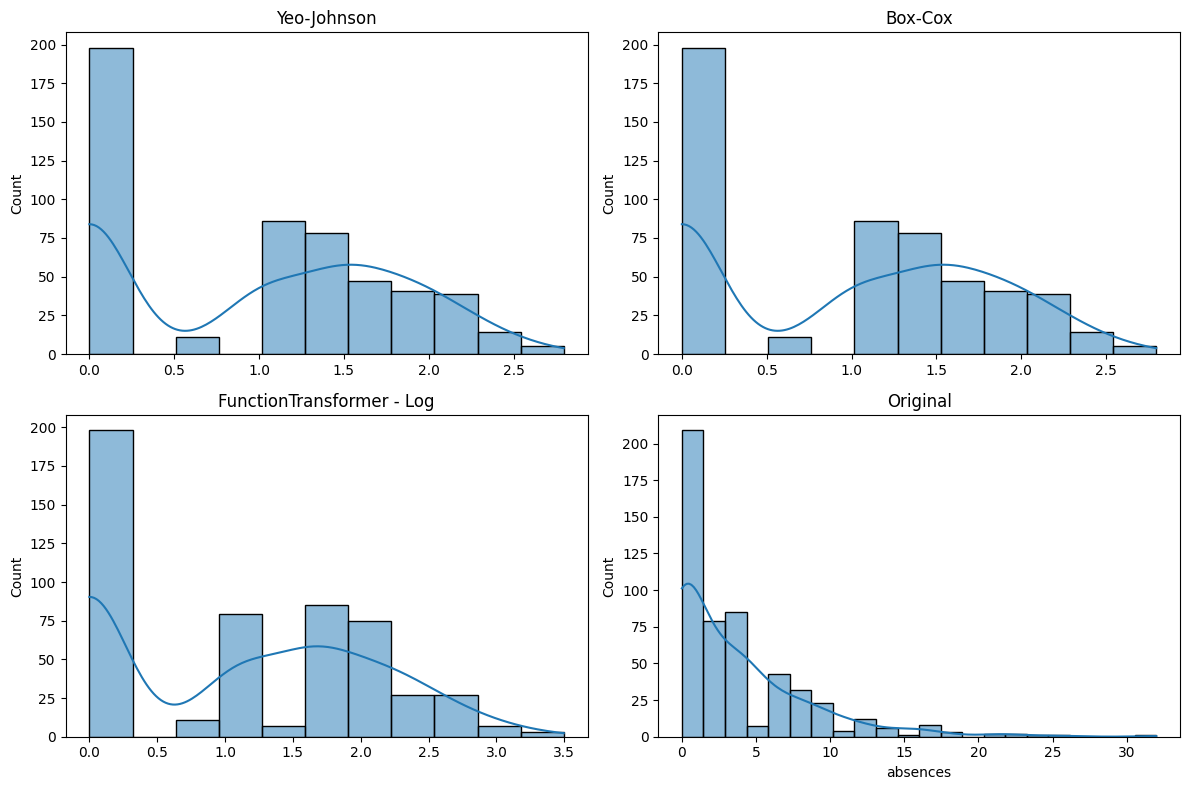

In [66]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(yeo.ravel(), kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Yeo-Johnson')

sns.histplot(box.ravel(), kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Box-Cox')

sns.histplot(log_values.ravel(), kde=True, ax=axes[1, 0])
axes[1, 0].set_title('FunctionTransformer - Log')

sns.histplot(X_train['absences'], kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Original')

plt.tight_layout()
plt.show()

In [76]:
cat_cols = ['sex', 'schoolsup', 'internet']

for col in cat_cols:
    print(f"\n{col}")
    print(X_train[col].value_counts())


sex
sex
F    294
M    225
Name: count, dtype: int64

schoolsup
schoolsup
no     466
yes     53
Name: count, dtype: int64

internet
internet
yes    392
no     127
Name: count, dtype: int64


In [77]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(
    drop='if_binary',
    handle_unknown='ignore'
)

X_train_cat = ohe.fit_transform(
    X_train[cat_cols]
)

print(ohe.get_feature_names_out())
print(X_train_cat.shape)

['sex_M' 'schoolsup_yes' 'internet_yes']
(519, 3)


##even tho there is no mising valuse its just for praice

In [78]:

from sklearn.impute import SimpleImputer

num_cols = ['age', 'studytime', 'failures', 'absences']

num_imputer = SimpleImputer(strategy='median')

cat_imputer = SimpleImputer(strategy='most_frequent')

X_train_num_imputed = num_imputer.fit_transform(
    X_train[num_cols]
)

X_train_cat_imputed = cat_imputer.fit_transform(
    X_train[cat_cols]
)

print("Numerical shape:", X_train_num_imputed.shape)
print("Categorical shape:", X_train_cat_imputed.shape)

Numerical shape: (519, 4)
Categorical shape: (519, 3)


In [93]:
from sklearn.base import BaseEstimator, TransformerMixin

class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5):
        self.factor = factor

    def fit(self, X, y=None):
        X_arr = np.asarray(X)
        Q1 = np.nanpercentile(X_arr, 25, axis=0)
        Q3 = np.nanpercentile(X_arr, 75, axis=0)
        IQR = Q3 - Q1
        self.lower_ = Q1 - self.factor * IQR
        self.upper_ = Q3 + self.factor * IQR
        return self

    def transform(self, X):
        return np.clip(np.asarray(X), self.lower_, self.upper_)

In [94]:
num_pipeline_A = ColumnTransformer([
    ('capped_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('capper', IQRCapper()),
        ('scaler', StandardScaler())
    ]), ['age', 'absences']),
    ('other_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), ['studytime', 'failures'])
])

preprocessor_A = ColumnTransformer([
    ('num', num_pipeline_A, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [95]:
num_pipeline_B = ColumnTransformer([
    ('log_absences', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('capper', IQRCapper()),
        ('log', FunctionTransformer(np.log1p)),
        ('scaler', StandardScaler())
    ]), ['absences']),
    ('capped_age', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('capper', IQRCapper()),
        ('scaler', StandardScaler())
    ]), ['age']),
    ('other_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), ['studytime', 'failures'])
])

preprocessor_B = ColumnTransformer([
    ('num', num_pipeline_B, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [96]:
from sklearn.preprocessing import PowerTransformer

num_pipeline_C = ColumnTransformer([
    ('capped_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('capper', IQRCapper()),
        ('power', PowerTransformer(method='yeo-johnson', standardize=True))
    ]), ['age', 'absences']),
    ('other_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('power', PowerTransformer(method='yeo-johnson', standardize=True))
    ]), ['studytime', 'failures'])
])

preprocessor_C = ColumnTransformer([
    ('num', num_pipeline_C, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [97]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['sex', 'schoolsup', 'internet']

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='if_binary',
        handle_unknown='ignore'
    ))
])

In [98]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [99]:
X_train_A = preprocessor_A.fit_transform(X_train)
X_test_A = preprocessor_A.transform(X_test)

X_train_B = preprocessor_B.fit_transform(X_train)
X_test_B = preprocessor_B.transform(X_test)

X_train_C = preprocessor_C.fit_transform(X_train)
X_test_C = preprocessor_C.transform(X_test)

print("A:", X_train_A.shape, X_test_A.shape)
print("B:", X_train_B.shape, X_test_B.shape)
print("C:", X_train_C.shape, X_test_C.shape)

A: (519, 7) (130, 7)
B: (519, 7) (130, 7)
C: (519, 7) (130, 7)


In [106]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score


models = {
    'Pipeline A (Standard)': Pipeline([
        ('preprocessor', preprocessor_A),
        ('model', LinearRegression())
    ]),
    'Pipeline B (Log + Standard)': Pipeline([
        ('preprocessor', preprocessor_B),
        ('model', LinearRegression())
    ]),
    'Pipeline C (Yeo-Johnson)': Pipeline([
        ('preprocessor', preprocessor_C),
        ('model', LinearRegression())
    ])
}

cv = KFold(n_splits=10, shuffle=True, random_state=42)
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

results = []

for name, pipe in models.items():
    # 1. Cross-validation on X_train (fits IQRCapper & scalers inside each fold)
    cv_scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    
    # 2. Fit on full X_train and evaluate on X_test
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    results.append({
        'Pipeline': name,
        'CV MAE': -cv_scores['test_MAE'].mean(),
        'CV RMSE': -cv_scores['test_RMSE'].mean(),
        'CV R2': cv_scores['test_R2'].mean(),
        'Test MAE': mean_absolute_error(y_test, y_pred),
        'Test RMSE': root_mean_squared_error(y_test, y_pred),
        'Test R2': r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index('Pipeline')
display(results_df.round(4))

,CV MAE,CV RMSE,CV R2,Test MAE,Test RMSE,Test R2
Pipeline,,,,,,
Pipeline A (Standard),9.5255,12.2441,0.1971,10.3481,13.3499,0.1581
Pipeline B (Log + Standard),9.5684,12.2713,0.1932,10.3184,13.3245,0.1613
Pipeline C (Yeo-Johnson),9.3589,11.9167,0.2369,10.0874,13.2389,0.1720


In [107]:
# 1. Include G1 and G2 in X, and set target y directly to G3 (0 to 20 scale)
X_with_grades = df[['sex', 'age', 'studytime', 'failures', 'schoolsup', 'internet', 'absences', 'G1', 'G2']]
y_g3 = df['G3']

X_tr, X_te, y_tr, y_te = train_test_split(X_with_grades, y_g3, test_size=0.2, random_state=42)

# 2. Update numerical columns to include G1 and G2
num_cols_grades = ['age', 'studytime', 'failures', 'absences', 'G1', 'G2']

num_pipeline_grades = ColumnTransformer([
    ('capped_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('capper', IQRCapper()),
        ('power', PowerTransformer(method='yeo-johnson', standardize=True))
    ]), ['age', 'absences']),
    ('other_num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('power', PowerTransformer(method='yeo-johnson', standardize=True))
    ]), ['studytime', 'failures', 'G1', 'G2'])
])

preprocessor_grades = ColumnTransformer([
    ('num', num_pipeline_grades, num_cols_grades),
    ('cat', cat_pipeline, cat_cols)
])

pipe_grades = Pipeline([
    ('preprocessor', preprocessor_grades),
    ('model', LinearRegression())
])

cv = KFold(n_splits=10, shuffle=True, random_state=42)
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
cv_scores = cross_validate(pipe_grades, X_tr, y_tr, cv=cv, scoring=scoring)

pipe_grades.fit(X_tr, y_tr)
y_pred = pipe_grades.predict(X_te)

print(f"CV Accuracy (R2):   {cv_scores['test_R2'].mean() * 100:.2f}%")
print(f"Test Accuracy (R2): {r2_score(y_te, y_pred) * 100:.2f}%")
print(f"CV Average Error:   ±{-cv_scores['test_MAE'].mean():.2f} marks (out of 20)")
print(f"Test Average Error: ±{mean_absolute_error(y_te, y_pred):.2f} marks (out of 20)")

CV Accuracy (R2):   82.10%
Test Accuracy (R2): 85.98%
CV Average Error:   ±0.86 marks (out of 20)
Test Average Error: ±0.77 marks (out of 20)


In [108]:
results_preview = pd.DataFrame({
    'Actual G3': y_te.values,
    'Predicted G3': np.round(y_pred, 2),
    'Error (Diff)': np.round(y_te.values - y_pred, 2)
})
display(results_preview.head(15))

,Actual G3,Predicted G3,Error (Diff)
0,19,19.09,-0.09
1,12,11.47,0.53
2,18,18.99,-0.99
3,11,11.18,-0.18
4,11,11.79,-0.79
5,17,17.24,-0.24
6,18,17.82,0.18
7,8,9.37,-1.37
8,10,10.60,-0.60
9,11,10.59,0.41


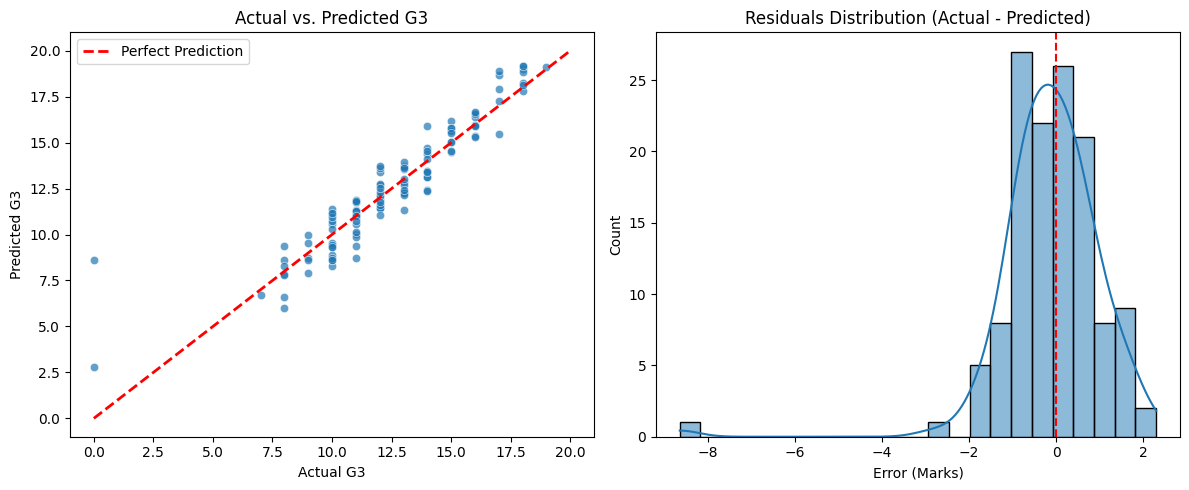

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Actual vs Predicted
sns.scatterplot(x=y_te, y=y_pred, alpha=0.7, ax=axes[0])
axes[0].plot([0, 20], [0, 20], 'r--', lw=2, label='Perfect Prediction')
axes[0].set_title('Actual vs. Predicted G3')
axes[0].set_xlabel('Actual G3')
axes[0].set_ylabel('Predicted G3')
axes[0].legend()

# Residual Distribution
residuals = y_te - y_pred
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].axvline(0, color='r', linestyle='--')
axes[1].set_title('Residuals Distribution (Actual - Predicted)')
axes[1].set_xlabel('Error (Marks)')

plt.tight_layout()
plt.show()

In [ ]:
joblib.dump(pipe_grades, 'student_g3_pipeline.pkl')
print("Model saved successfully!")

# Example: Predict a new student's final G3 score
sample_student = pd.DataFrame([{
    'sex': 'F', 'age': 17, 'studytime': 3, 'failures': 0,
    'schoolsup': 'no', 'internet': 'yes', 'absences': 2,
    'G1': 14, 'G2': 15
}])
print(f"Predicted G3: {pipe_grades.predict(sample_student)[0]:.2f} / 20")

In [ ]:
%pip install streamlit


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from sklearn.base import BaseEstimator, TransformerMixin

# Required ONLY because IQRCapper is a custom class inside your saved pipeline
class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, factor=1.5): self.factor = factor
    def fit(self, X, y=None):
        Q1, Q3 = np.nanpercentile(X, [25, 75], axis=0)
        self.lower_, self.upper_ = Q1 - self.factor * (Q3 - Q1), Q3 + self.factor * (Q3 - Q1)
        return self
    def transform(self, X): return np.clip(np.asarray(X), self.lower_, self.upper_)

model = joblib.load('student_g3_pipeline.pkl')

st.title("🎓 Student G3 Predictor")

# 9 UI inputs for the 9 columns your pipeline expects
data = {
    'sex': st.selectbox("Sex", ["F", "M"]),
    'age': st.number_input("Age", 15, 22, 17),
    'studytime': st.selectbox("Study Time (1-4)", [1, 2, 3, 4]),
    'failures': st.selectbox("Failures", [0, 1, 2, 3]),
    'schoolsup': st.selectbox("School Support", ["no", "yes"]),
    'internet': st.selectbox("Internet", ["yes", "no"]),
    'absences': st.number_input("Absences", 0, 93, 2),
    'G1': st.slider("G1 Score", 0, 20, 12),
    'G2': st.slider("G2 Score", 0, 20, 12),
}

# Your entire pipeline runs in 1 line:
if st.button("Predict"):
    pred = np.clip(model.predict(pd.DataFrame([data]))[0], 0, 20)
    st.success(f"Predicted G3: {pred:.2f} / 20")

In [119]:
m=df.iloc[219:226]

In [120]:
m

,sex,age,studytime,failures,schoolsup,internet,absences,G1,G2,G3,total_score,percentage
219,F,17,3,1,no,yes,14,8,9,8,25,41.67
220,F,16,2,0,no,yes,2,11,11,12,34,56.67
221,F,16,2,0,no,yes,4,14,15,15,44,73.33
222,F,16,1,0,no,no,2,12,13,13,38,63.33
223,F,17,3,0,no,yes,0,11,12,12,35,58.33
224,F,19,4,0,no,yes,4,12,12,12,36,60.00
225,M,17,2,0,no,yes,15,13,12,12,37,61.67
